In [1]:
!pip install imbalanced-learn joblib

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, roc_auc_score, confusion_matrix
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

import warnings
warnings.filterwarnings('ignore')

In [5]:
# Load the main dataset and thresholds
df = pd.read_csv('hemolysis_index_results.csv')
thresholds = pd.read_csv('redraw_thresholds.csv')

# Merge to get the threshold for each orderable
# The common column is 'ORDERABLE' (not 'specimen_type')
df = df.merge(thresholds, on='ORDERABLE', how='left')

# Create the binary target variable: 1 if hemolysis index exceeds threshold, else 0
# The column names are 'HEMOLYSIS_INDEX' and 'HI_REDRAW_THRESHOLD'
df['target'] = (df['HEMOLYSIS_INDEX'] > df['HI_REDRAW_THRESHOLD']).astype(int)

print(f"Dataset shape: {df.shape}")
print(f"Class Distribution:\n{df['target'].value_counts(normalize=True)}")

Dataset shape: (101174, 18)
Class Distribution:
target
0    0.989572
1    0.010428
Name: proportion, dtype: float64


In [10]:
# --- NEW: Clean the PATIENT_AGE column to fix the '>89' string error ---
# This extracts the digits (e.g., converts '>89' to 89.0) and converts the column to numeric
df['PATIENT_AGE'] = df['PATIENT_AGE'].astype(str).str.extract(r'(\d+)').astype(float)

# Addressing Feedback: Group Collector ID to prevent identifier-related overfitting
# We bucket collectors into high-volume vs low-volume based on frequency
collector_counts = df['COLLECTOR_ID'].value_counts()
high_volume_threshold = collector_counts.quantile(0.75) # Top 25% as high volume
df['collector_group'] = df['COLLECTOR_ID'].apply(
    lambda x: 'high_volume' if collector_counts.get(x, 0) > high_volume_threshold else 'low_volume'
)

# Select features and target
# Note: Using uppercase column names to match the Kaggle dataset
features = ['PATIENT_AGE', 'PATIENT_SEX', 'PATIENT_RACE', 'NURSING_UNIT',
            'ENCOUNTER_TYPE', 'MEDICAL_SERVICE', 'ORDERABLE',
            'collector_group', 'DRAW_SITE', 'COLLECTION_DAY', 'COLLECTION_TIME']
target = 'target'

# Addressing Feedback: Leakage-safe splitting (Grouping by patient)
# Safely detect the patient grouping column (differs based on dataset version)
if 'PATIENT_ID' in df.columns:
    group_col = 'PATIENT_ID'
elif 'ENCOUNTER_ID' in df.columns:
    group_col = 'ENCOUNTER_ID'
elif 'SPECIMEN_ID' in df.columns:
    group_col = 'SPECIMEN_ID'
else:
    raise ValueError("Could not find a patient/encounter ID column for grouping.")

X = df[features]
y = df[target]
groups = df[group_col]

# Define preprocessing for numerical and categorical features
numeric_features = ['PATIENT_AGE']
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_features = ['PATIENT_SEX', 'PATIENT_RACE', 'NURSING_UNIT', 'ENCOUNTER_TYPE',
                        'MEDICAL_SERVICE', 'ORDERABLE', 'collector_group',
                        'DRAW_SITE', 'COLLECTION_DAY', 'COLLECTION_TIME']
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])
print("Preprocessing pipeline defined successfully and PATIENT_AGE cleaned.")

Preprocessing pipeline defined successfully and PATIENT_AGE cleaned.


In [11]:
# Addressing Feedback: Define leakage-safe splitting (Grouping by patient)
# First split: 80% Train, 20% Temp (Validation + Test)
gss = GroupShuffleSplit(n_splits=1, train_size=0.8, random_state=42)
train_idx, temp_idx = next(gss.split(X, y, groups))

X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_temp, y_temp = X.iloc[temp_idx], y.iloc[temp_idx]
groups_temp = groups.iloc[temp_idx]

# Second split: Split the 20% Temp into 10% Validation and 10% Test
gss_val = GroupShuffleSplit(n_splits=1, train_size=0.5, random_state=42)
val_idx, test_idx = next(gss_val.split(X_temp, y_temp, groups_temp))

X_val, y_val = X_temp.iloc[val_idx], y_temp.iloc[val_idx]
X_test, y_test = X_temp.iloc[test_idx], y_temp.iloc[test_idx]

print(f"Training set: {X_train.shape[0]} samples")
print(f"Validation set: {X_val.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")

Training set: 80401 samples
Validation set: 10540 samples
Test set: 10233 samples


In [12]:
# Addressing Feedback: Apply resampling (SMOTE) only within training folds via Pipeline
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42, n_estimators=100)
}

results = {}

for name, model in models.items():
    # Create pipeline with preprocessing, SMOTE, and model
    pipeline = ImbPipeline(steps=[
        ('preprocessor', preprocessor),
        ('smote', SMOTE(random_state=42)),
        ('classifier', model)
    ])

    # Train the model
    pipeline.fit(X_train, y_train)

    # Evaluate on validation set
    y_pred = pipeline.predict(X_val)
    y_prob = pipeline.predict_proba(X_val)[:, 1]

    # Calculate metrics
    results[name] = {
        "Accuracy": accuracy_score(y_val, y_pred),
        "Sensitivity (Recall)": recall_score(y_val, y_pred),
        "Specificity": recall_score(y_val, y_pred, pos_label=0),
        "Precision": precision_score(y_val, y_pred),
        "F1-Score": f1_score(y_val, y_pred),
        "ROC-AUC": roc_auc_score(y_val, y_prob)
    }

    print(f"--- {name} ---")
    for metric, score in results[name].items():
        print(f"{metric}: {score:.4f}")
    print()

# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results).T
print(results_df)

--- Logistic Regression ---
Accuracy: 0.8627
Sensitivity (Recall): 0.4911
Specificity: 0.8667
Precision: 0.0381
F1-Score: 0.0706
ROC-AUC: 0.7952

--- Decision Tree ---
Accuracy: 0.9817
Sensitivity (Recall): 0.0536
Specificity: 0.9917
Precision: 0.0645
F1-Score: 0.0585
ROC-AUC: 0.5226

--- Random Forest ---
Accuracy: 0.9894
Sensitivity (Recall): 0.0000
Specificity: 1.0000
Precision: 0.0000
F1-Score: 0.0000
ROC-AUC: 0.7206

                     Accuracy  Sensitivity (Recall)  Specificity  Precision  \
Logistic Regression  0.862713              0.491071     0.866705   0.038062   
Decision Tree        0.981689              0.053571     0.991657   0.064516   
Random Forest        0.989374              0.000000     1.000000   0.000000   

                     F1-Score   ROC-AUC  
Logistic Regression  0.070649  0.795173  
Decision Tree        0.058537  0.522614  
Random Forest        0.000000  0.720611  


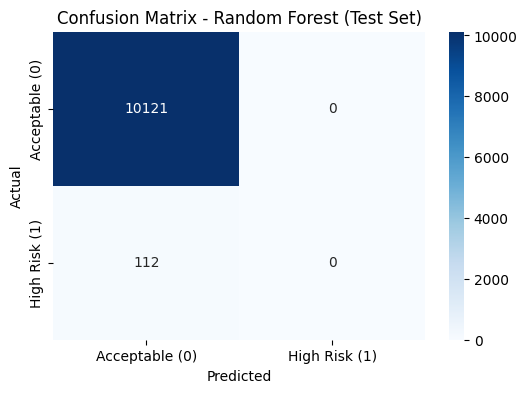

Model saved successfully as 'hemolysis_rf_model.pkl'


In [13]:
# Select best model (Random Forest)
best_model = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('classifier', RandomForestClassifier(random_state=42, n_estimators=100))
])

best_model.fit(X_train, y_train)
y_test_pred = best_model.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Acceptable (0)', 'High Risk (1)'],
            yticklabels=['Acceptable (0)', 'High Risk (1)'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix - Random Forest (Test Set)')
plt.show()

# Save the model for the Streamlit app
import joblib
joblib.dump(best_model, 'hemolysis_rf_model.pkl')
print("Model saved successfully as 'hemolysis_rf_model.pkl'")